# 3. Binary Images

Practice for module 3: sequential labelling with an equivalence table, 4- vs 8-connectivity and the
checkerboard paradox, the Euler number, area / centroid / orientation from moments, roundedness, and local
operations (shrinking and growing) defined by neighbourhood rules.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

## 3.1 Sequential labelling

Raster scan. For each foreground pixel look at the already-visited neighbours (left and up for
4-connectivity, plus the two upper diagonals for 8-connectivity). No labelled neighbour → new label; one or
more → take the smallest and record the others as equivalent. A second pass replaces every label by its
class representative (union–find).

components: 4-connectivity 9, 8-connectivity 4 (the diagonal line breaks up under 4-connectivity)


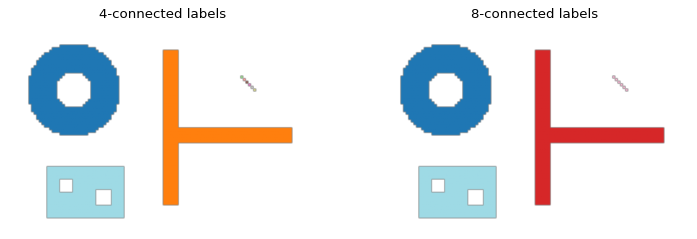

In [2]:
def label(b, conn=4):
    L = np.zeros(b.shape, int); parent = [0]
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]; a = parent[a]
        return a
    prev = [(0, -1), (-1, 0)] + ([(-1, -1), (-1, 1)] if conn == 8 else [])
    H, W = b.shape
    for y in range(H):
        for x in range(W):
            if not b[y, x]: continue
            ns = [L[y + dy, x + dx] for dy, dx in prev if 0 <= y + dy and 0 <= x + dx < W and L[y + dy, x + dx]]
            if not ns:
                parent.append(len(parent)); L[y, x] = len(parent) - 1
            else:
                roots = {find(n) for n in ns}; m = min(roots); L[y, x] = m
                for r in roots: parent[r] = m
    roots = np.array([find(a) for a in range(len(parent))])
    _, compact = np.unique(roots, return_inverse=True)
    return compact[L], len(np.unique(roots)) - 1

yy, xx = np.mgrid[:80, :120]
img = np.zeros((80, 120), bool)
img[(xx - 25) ** 2 + (yy - 25) ** 2 < 18 ** 2] = True
img[(xx - 25) ** 2 + (yy - 25) ** 2 < 7 ** 2] = False                   # a ring (1 hole)
img[10:70, 60:66] = True; img[40:46, 60:110] = True                    # an L shape
img[55:75, 15:45] = True; img[60:65, 20:25] = False; img[64:70, 34:40] = False   # block with 2 holes
for k in range(6): img[20 + k, 90 + k] = True                          # a diagonal line
lab4, n4 = label(img, 4); lab8, n8 = label(img, 8)
print(f"components: 4-connectivity {n4}, 8-connectivity {n8} (the diagonal line breaks up under 4-connectivity)")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for a, l, t in zip(axes, [lab4, lab8], ["4-connected labels", "8-connected labels"]):
    a.imshow(np.where(l > 0, l, np.nan), cmap="tab20"); a.set_title(t); a.axis("off")
plt.show()

## 3.2 Euler number and the checkerboard paradox

Euler number = components − holes; holes are the background components that do not touch the border. The
background must use the *other* connectivity. With 8-connectivity for both, a diagonal ring is closed (its
inside should be a hole) and yet the background leaks through the diagonal gaps, which contradicts the
Jordan curve theorem.

In [3]:
def euler(b, fg=8):
    _, comps = label(b, fg)
    bg, nbg = label(np.pad(~b, 1, constant_values=True), 12 - fg)    # padding joins all outside background
    return comps - (nbg - 1)

print("Euler number of the test image (8-fg / 4-bg):", euler(img, 8), "(4 objects, 3 holes -> 1)")
diamond = np.zeros((7, 7), bool)
for y, x in [(1, 3), (2, 2), (2, 4), (3, 1), (3, 5), (4, 2), (4, 4), (5, 3)]: diamond[y, x] = True
_, fg8 = label(diamond, 8); _, bg8 = label(~diamond, 8); _, bg4 = label(~diamond, 4)
print(f"diagonal ring: foreground 8-connected -> {fg8} object; background 8-connected -> {bg8} region "
      f"(no hole!), background 4-connected -> {bg4} regions (1 hole)")

Euler number of the test image (8-fg / 4-bg): 1 (4 objects, 3 holes -> 1)
diagonal ring: foreground 8-connected -> 1 object; background 8-connected -> 1 region (no hole!), background 4-connected -> 2 regions (1 hole)


## 3.3 Area, centroid, orientation, roundedness

Area is the zeroth moment, the centroid comes from the first moments. With the second moments about the
centroid `a = Σx'², b = 2Σx'y', c = Σy'²`, the axis of least inertia has `tan 2θ = b / (a − c)`.
`E_min / E_max` measures roundedness: 1 for a circle (and for a square), near 0 for a thin line.

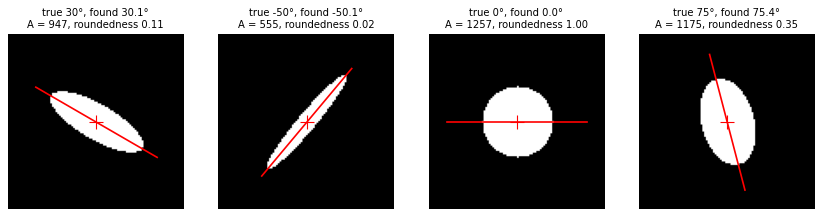

square: roundedness 1.00 (same as a circle, so it is not a full shape descriptor)


In [4]:
def shape_props(b):
    y, x = np.nonzero(b); A = len(x); xc, yc = x.mean(), y.mean()
    xp, yp = x - xc, y - yc
    a, bb, c = (xp ** 2).sum(), 2 * (xp * yp).sum(), (yp ** 2).sum()
    th = 0.5 * np.arctan2(bb, a - c)
    E = lambda t: a * np.sin(t) ** 2 - bb * np.sin(t) * np.cos(t) + c * np.cos(t) ** 2
    return A, (xc, yc), th, E(th) / E(th + np.pi / 2)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, (ang, ax_len) in zip(axes, [(30, (30, 10)), (-50, (35, 5)), (0, (20, 20)), (75, (25, 15))]):
    t = np.deg2rad(ang); yy, xx = np.mgrid[:100, :100] - 50
    u, v = xx * np.cos(t) + yy * np.sin(t), -xx * np.sin(t) + yy * np.cos(t)
    b = (u / ax_len[0]) ** 2 + (v / ax_len[1]) ** 2 <= 1
    A, (xc, yc), th, rnd = shape_props(b)
    ax.imshow(b, cmap="gray"); ax.plot(xc, yc, "r+", ms=12)
    ax.plot(xc + 40 * np.cos(th) * np.array([-1, 1]), yc + 40 * np.sin(th) * np.array([-1, 1]), "r")
    ax.set_title(f"true {ang}°, found {np.rad2deg(th):.1f}°\nA = {A}, roundedness {rnd:.2f}", fontsize=9); ax.axis("off")
plt.show()
sq = np.zeros((60, 60), bool); sq[10:50, 10:50] = True
print(f"square: roundedness {shape_props(sq)[3]:.2f} (same as a circle, so it is not a full shape descriptor)")

## 3.4 Local operations

A rule on each pixel and its 8 neighbours. Shrinking removes foreground pixels that touch the background;
growing adds background pixels that touch the foreground. Shrink-then-grow removes small specks; grow-then-shrink
fills small gaps.

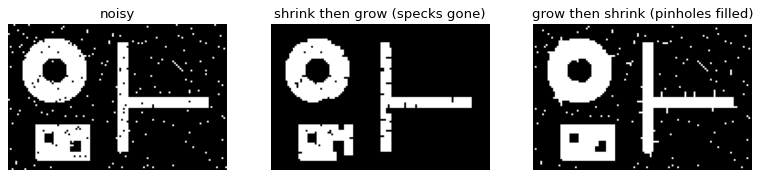

In [5]:
def neighbours(b):
    p = np.pad(b, 1)
    return [p[1 + dy:1 + dy + b.shape[0], 1 + dx:1 + dx + b.shape[1]] for dy in (-1, 0, 1) for dx in (-1, 0, 1)]
shrink = lambda b: np.logical_and.reduce(neighbours(b))
grow = lambda b: np.logical_or.reduce(neighbours(b))

noisy = img.copy()
noisy[rng.random(img.shape) < 0.02] = True                        # specks
noisy[rng.random(img.shape) < 0.03] = False                       # pinholes
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for a, b, t in zip(axes, [noisy, grow(shrink(noisy)), shrink(grow(noisy))],
                   ["noisy", "shrink then grow (specks gone)", "grow then shrink (pinholes filled)"]):
    a.imshow(b, cmap="gray"); a.set_title(t); a.axis("off")
plt.show()